<a href="https://colab.research.google.com/github/emiliewolter/2026_Intro_Python/blob/main/FEEDBACK_WOLTER_EMILIE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exercise chosen : 1.6-geospatial-vector-data-environmental-exercises, question 4

In order to get to question 4, the first steps were copied and just have to be run.


In [1]:
# Pre-supplied: download and cache the two real data files.
import pooch

states_path = pooch.retrieve(
    url="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-I/gz_2010_us_040_00_5m.json",
    known_hash="sha256:7a8c022e063a34a83f35984cde6c81992ece5983f8cc4459ed02e40687739573",
    fname="us_states.geojson",
    path=pooch.os_cache("mlees"),
)
track_path = pooch.retrieve(
    url="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-I/florence.csv",
    known_hash="sha256:385691583ee41682a1c905e042c56ea362609fb04645934bdda7911c55c8b63f",
    fname="florence.csv",
    path=pooch.os_cache("mlees"),
)

# Import geopandas (as gpd), pandas, and matplotlib
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Read the data with the geopandas function

# states_file définie dans la cellule au dessus.

from pathlib import Path
from shapely.geometry import Polygon
Path("_files").mkdir(exist_ok=True)


country = gpd.read_file(states_path)

In [3]:
# Print out the first few lines of the data
country.head(3)

# la géométrie est des polygones et des multipolygones.

,GEO_ID,STATE,NAME,LSAD,CENSUSAREA,geometry
0,0400000US01,01,Alabama,,50645.326,"MULTIPOLYGON (((-88.12466 30.28364, -88.08681 ..."
1,0400000US02,02,Alaska,,570640.950,"MULTIPOLYGON (((-166.10574 53.98861, -166.0752..."
2,0400000US04,04,Arizona,,113594.084,"POLYGON ((-112.53859 37.00067, -112.53454 37.0..."


# Question 4

In [10]:
# Model used, from class 1.6
# "The cell below flags each station with .isin(), which checks whether a value appears in a given list or Series
#  here, whether a station's name is among the names the spatial join found inside a hazard zone — and maps the result.""

#flagged = stations.assign(in_hazard=stations["name"].isin(in_hazard["name"]))
#fig, ax = plt.subplots(figsize=(5, 5))
#zones_wgs84.boundary.plot(ax=ax, color="tab:red", linewidth=1)
#flagged.plot(ax=ax, column="in_hazard", categorical=True, legend=True, markersize=40)
#ax.set_xlabel("longitude (°E)")
#ax.set_ylabel("latitude (°N)")
#ax.set_title("stations and hazard zones (EPSG:4326)")
#plt.show()

####### Comment
# Here we want to keep the in_hazard which are stations inside a certain zone, the same as our exemple.

####### Application to the exercise.

# 1. Defining the polygons we do not want
excluded = ["Alaska", "Hawaii"]

# 2. Keeping lines without the two polygons
country_filtered = country.assign(excluded=country["NAME"].isin(excluded["NAME"]))

# 3. Plotting the figure with the filtered dataset.
fig, ax = plt.subplots(figsize=(30, 20))          # choosing the figsize = 30*20
country_filtered.plot(ax=ax, legend=True, markersize=40)
ax.set_xlabel("longitude (°E)")                   # Axis labels
ax.set_ylabel("latitude (°N)")                    # Axis labels
ax.set_title("Country except Alaska and Hawaii")  # Plot title
plt.show()                                        # Showing the plot



TypeError: list indices must be integers or slices, not str

Problem encountered:
Using the same method as the course exemple doesnt work.
The error is indicating a type of variable problem.
Excluded is not a geodataframe, but a list of names (str). We do not need to specify the name column in .isin as it only has 1 column.
The exemple from the class took a dataframe with multiple columns.


# Correction

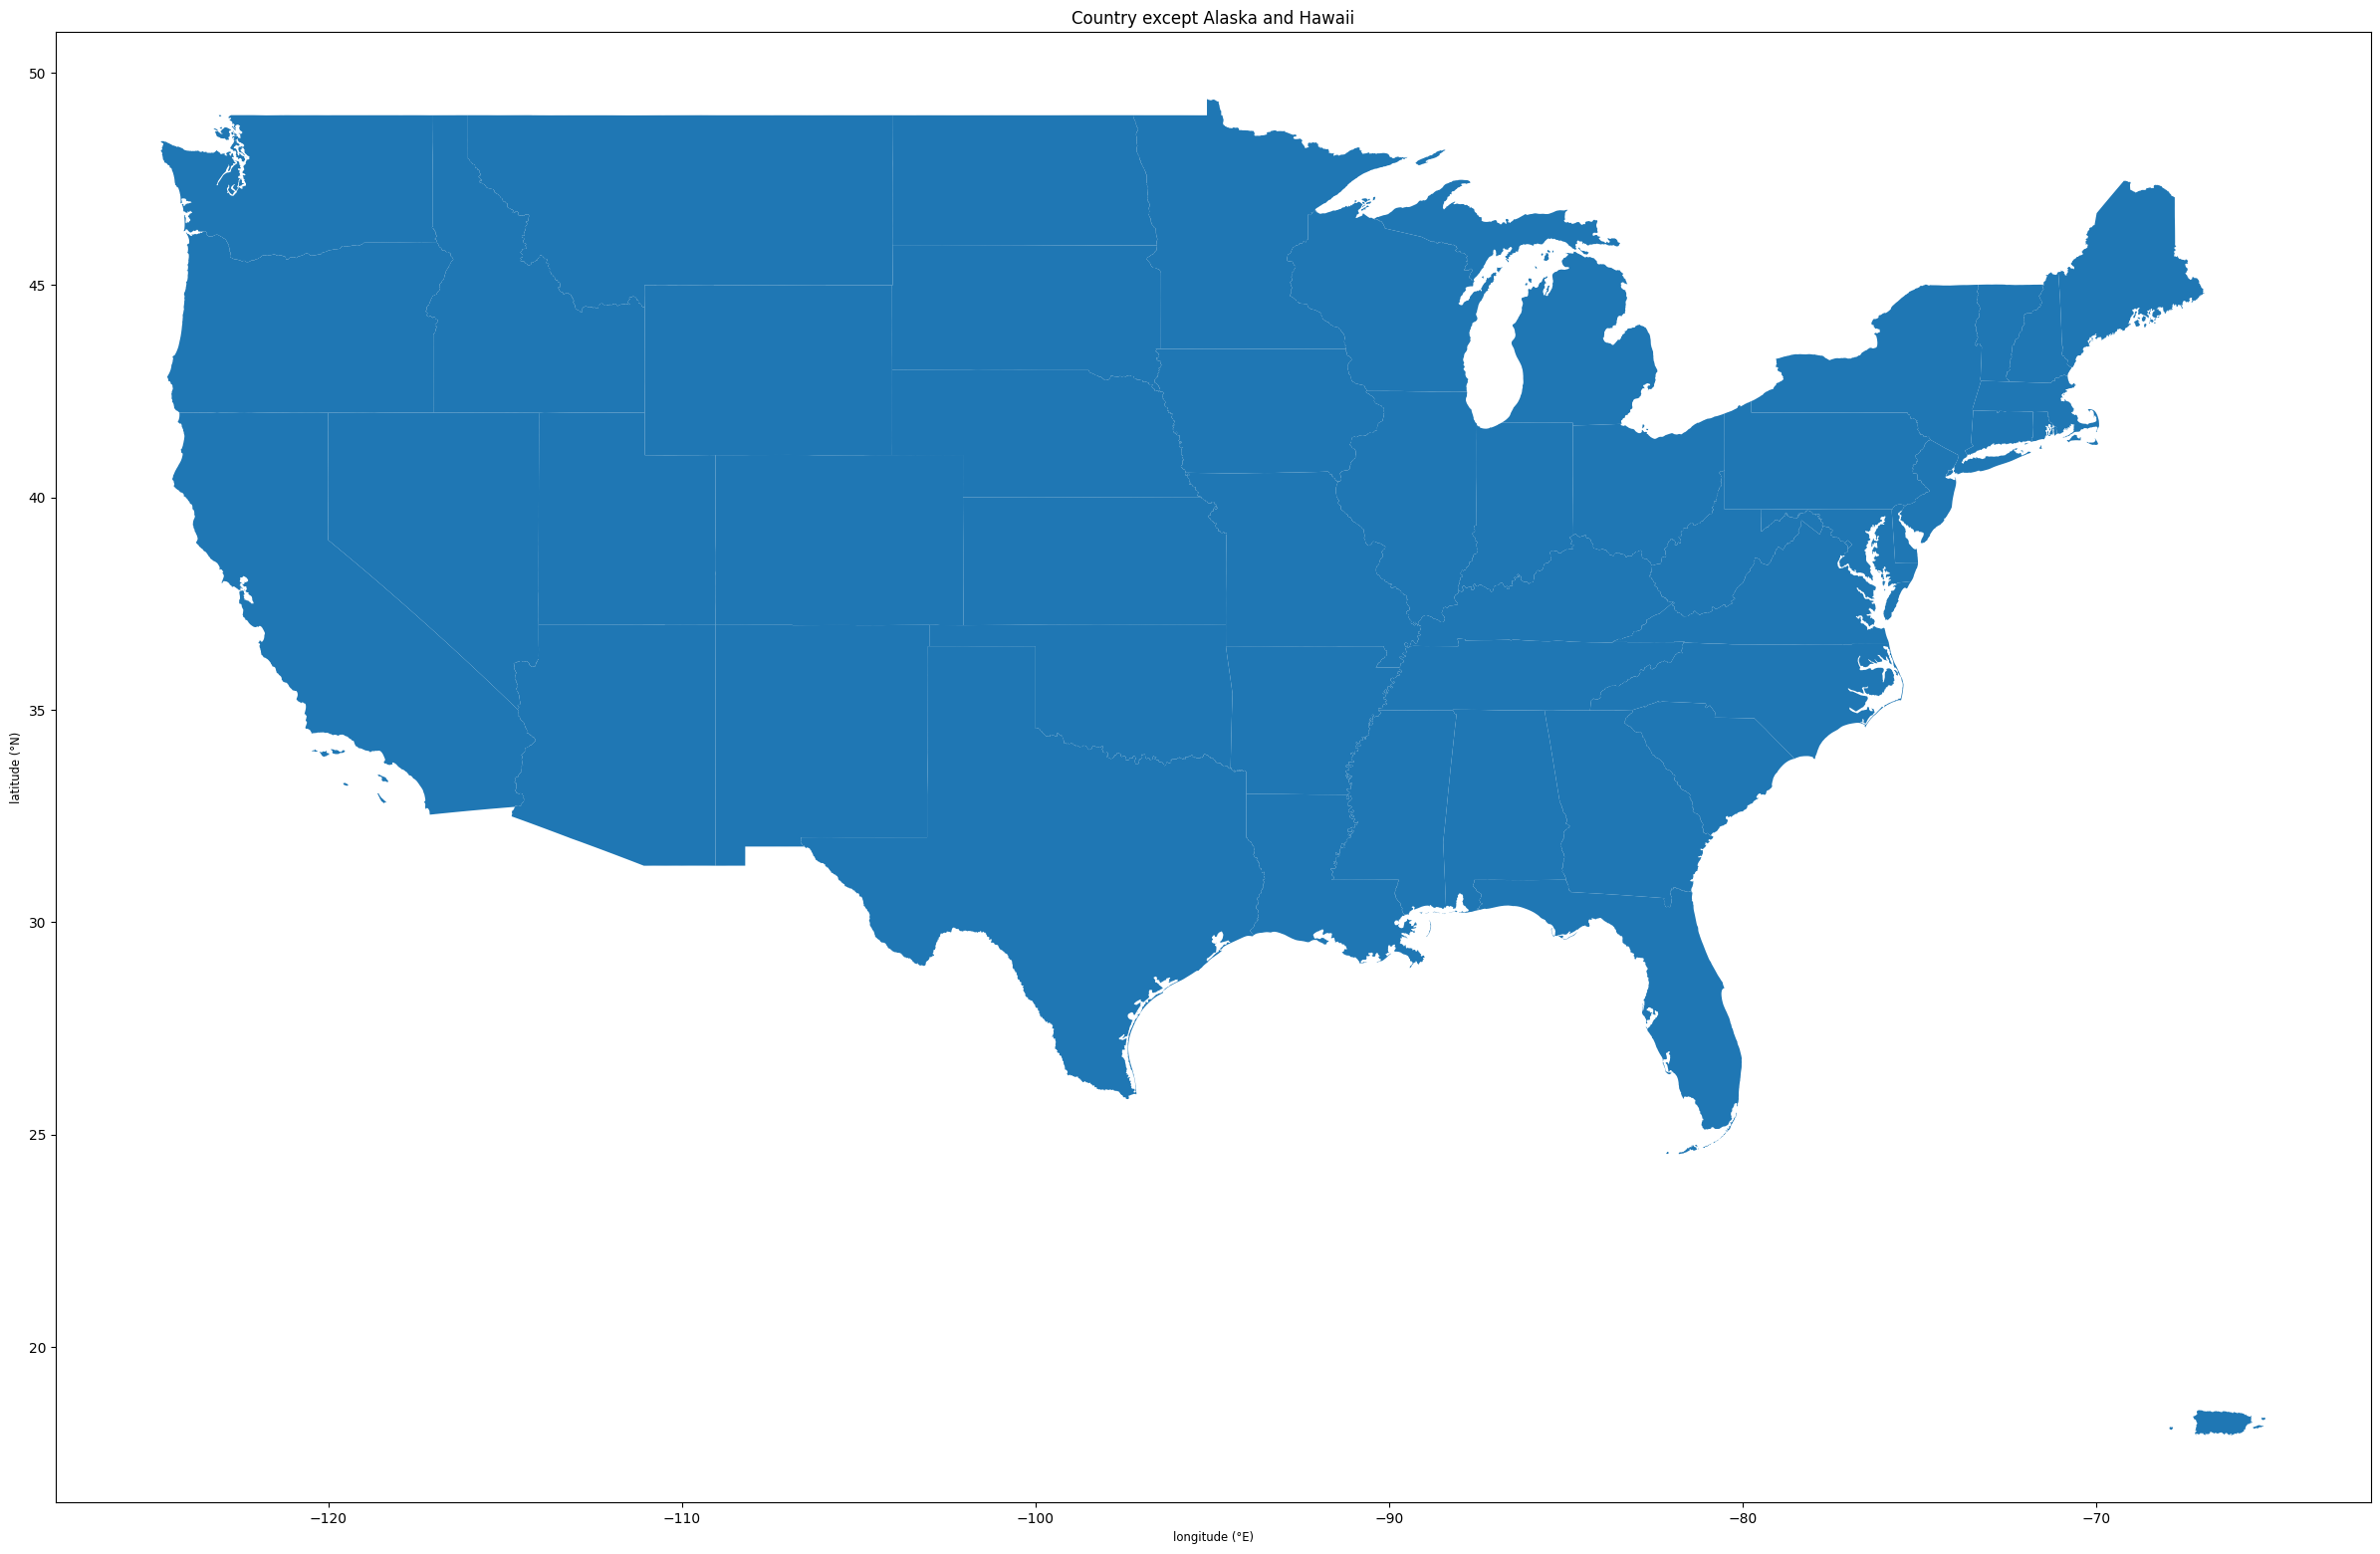

In [5]:
# 1. Defining the polygons we want to remove
excluded = ["Alaska", "Hawaii"]

#    This line filters a geodataframe gdf (country) to remove certain rows
#    and stores the result in a new variable (country_filtered)
#    country["NAME"] selects the column NAME
#    .isin(excluded) goes through the NAME column and return a True or False value
#    if the value (name of the state) is in excluded, it returns True
#    we want to remove the excluded, so we inverse the True values to a False value,
#    and the False values to a True value.
#    The ~ is returning that, inversing true and false values.

country_filtered = country[~country["NAME"].isin(excluded)]

# 3. Plotting the figure with the filtered dataset.
fig, ax = plt.subplots(figsize=(30, 20))          # choosing the figsize = 30*20
country_filtered.plot(ax=ax, legend=True, markersize=40)
ax.set_xlabel("longitude (°E)")                   # Axis labels
ax.set_ylabel("latitude (°N)")                    # Axis labels
ax.set_title("Country except Alaska and Hawaii")  # Plot title
plt.show()                                        # Showing the plot